# 02 · Modelling the Likelihood of Procurement Failure

**PhilGEPS procurement-failure risk · Notebook 2 of 3 · Roadmap step 6**
**Input:** `data/processed/bids_public_bidding.parquet` from notebook 01 (one row per Public Bidding bid, PhilGEPS 1.5 + 2.0, 2023 Q1 – 2026 Q2, `Closed` bids removed).
**Target:** `Target_Failed` = 1 if the bid ended in a failed bidding **or was cancelled**, 0 if it was awarded. Other statuses are excluded (notebook 01, §5.2).

## Approach

1. **Split.** The merged 1.5 + 2.0 bid table is split at random into **train (70%)**, **validation (15%)** and **test (15%)**, stratified by outcome and source system. The split is by **notice group**: re-advertisements of the same notice (same procuring entity, title and budget) always land in the same set, so the model is never tested on a near-copy of a training notice. Bids published in **2025 Q3–Q4** are left out of training and evaluation, because their outcomes are incomplete in the source data (notebook 01, §5.3). This differs from LT8, which split by year. The year-based view is kept as a robustness check in notebook 03, because a random split mixes periods and can overstate how well the model works on future notices.
2. **Baselines.** A majority-class model, and a random ranking.
3. **Original 5 features** (as in LT8 §6.1): log approved budget, funding source, procurement category, region, publication month. Four models are compared on the validation set: logistic regression, decision tree, random forest and histogram gradient boosting.
4. **Expanded features**, all available at publication: the original 5 plus bidding-window length, number of line items, contract duration, classification, organisation type, government branch, funding instrument, applicable procurement rules, lot type, publication weekday, source system, a multi-funding-source flag, and the **re-advertisement history** (number of earlier attempts and the outcome of the latest one; notebook 01, §5.8).
5. **Final model.** The best combination on validation PR-AUC is chosen and evaluated **once** on the test set. Its scores are calibrated on the validation set, so they can be read as probabilities of failure.
6. **Sensitivity.** The final configuration is refitted with only `Failed` counted as failure (Cancelled bids left out, §6.10), and with the 2025 Q3–Q4 bids added back (§6.11).

**Metrics.** Failed or cancelled bids are about 20% of labelled bids, so accuracy is not informative: predicting "awarded" for every bid is 80% accurate. The metrics used are:

- **ROC-AUC:** ranking quality overall.
- **PR-AUC (average precision):** ranking quality focused on the failed class.
- **Review-queue metrics:** precision, recall and lift when staff review only the top *k*% of notices by predicted risk (LT8 §6.2).

In [1]:
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (PrecisionRecallDisplay, RocCurveDisplay, brier_score_loss)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

import procurement_failure as pf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pf.MODELS.mkdir(parents=True, exist_ok=True)

bids = pd.read_parquet(pf.BIDS)
all_labelled = bids[bids["Target_Failed"].notna()].reset_index(drop=True)
in_scope = all_labelled["in_model_scope"]
print(f"Bids: {len(bids):,} | labelled: {len(all_labelled):,} | in model scope: {in_scope.sum():,} "
      f"(2025 Q3–Q4 excluded: {(~in_scope).sum():,}) | failure rate in scope: {all_labelled.loc[in_scope, 'Target_Failed'].mean() * 100:.2f}%")

Bids: 629,921 | labelled: 615,398 | in model scope: 580,220 (2025 Q3–Q4 excluded: 35,178) | failure rate in scope: 19.12%


## 6.1 Train / validation / test split on the merged dataset

`pf.grouped_split` assigns whole **notice groups** (a notice and its re-advertisements) to train, validation or test, stratified on outcome × source system. Each set therefore keeps the same failure rate and the same share of PhilGEPS 2.0 bids, and no notice has a re-advertised twin on the other side of the split.

The split is drawn once for **all** labelled bids, including 2025 Q3–Q4, so the sensitivity check in §6.11 can add those bids back without moving any other bid. The main analysis then keeps the in-scope bids. The assignment is saved so that notebook 03 uses exactly the same test set.

In [2]:
all_labelled["split"] = pf.grouped_split(all_labelled, "Target_Failed")
all_labelled[pf.KEY + ["split"]].to_parquet(pf.SPLITS, index=False)
print("Notice groups in more than one set:", int(all_labelled.groupby("notice_group")["split"].nunique().gt(1).sum()))

labelled = all_labelled[all_labelled["in_model_scope"]].reset_index(drop=True)
split_summary = labelled.groupby(["split", "Source System"], observed=True)["Target_Failed"].agg(
    Bids="size", Failed="sum", **{"Failure rate": "mean"})
display(split_summary)

train = labelled[labelled.split == "train"]
val = labelled[labelled.split == "validation"]
test = labelled[labelled.split == "test"]
y_train, y_val, y_test = train.Target_Failed.astype(int), val.Target_Failed.astype(int), test.Target_Failed.astype(int)
print(f"train {len(train):,} | validation {len(val):,} | test {len(test):,}")

Notice groups in more than one set: 0


Bids      Failed  Failure rate
split      Source System                                  
test       1.5             85713 16,201.0000        0.1890
           2.0              1272    485.0000        0.3813
train      1.5            400055 75,336.0000        0.1883
           2.0              5943  2,285.0000        0.3845
validation 1.5             85974 16,146.0000        0.1878
           2.0              1263    484.0000        0.3832

train 405,998 | validation 87,237 | test 86,985


## 6.2 Baselines

- **Majority class:** always predicts *awarded*. It shows why accuracy is misleading: high accuracy, zero failures detected.
- **Random ranking:** the expected PR-AUC equals the failure rate, and lift is 1 at every review share.

In [3]:
majority = DummyClassifier(strategy="most_frequent").fit(train[["log_approved_budget"]], y_train)
pred = majority.predict(val[["log_approved_budget"]])
print(f"Majority-class validation accuracy: {(pred == y_val).mean() * 100:.1f}% | failures detected: {int((pred[y_val == 1] == 1).sum())} of {int(y_val.sum()):,}")
print(f"Random-ranking validation PR-AUC (= failure rate): {y_val.mean():.4f} | ROC-AUC: 0.5 | lift: 1.0")

Majority-class validation accuracy: 80.9% | failures detected: 0 of 16,630
Random-ranking validation PR-AUC (= failure rate): 0.1906 | ROC-AUC: 0.5 | lift: 1.0


## 6.3 Candidate models

Every model uses the same preprocessing:

- **Logistic regression, decision tree, random forest:** numeric features are median-imputed and standardised. Categorical features are one-hot encoded, with categories seen fewer than 50 times grouped as *infrequent*.
- **Gradient boosting:** uses native categorical splits.

All four use class weighting, so the rare failed class is not ignored. Settings are fixed and moderate rather than tuned. As LT8 concluded, the priority is a sound evaluation, not the last point of AUC.

In [4]:
def make_models(numeric, categorical):
    onehot = lambda: pf.one_hot_preprocessor(numeric, categorical)
    return {
        "Logistic regression": Pipeline([("prep", onehot()), ("model", LogisticRegression(
            class_weight="balanced", max_iter=3000))]),
        "Decision tree": Pipeline([("prep", onehot()), ("model", DecisionTreeClassifier(
            max_depth=12, min_samples_leaf=100, class_weight="balanced", random_state=pf.RANDOM_STATE))]),
        "Random forest": Pipeline([("prep", onehot()), ("model", RandomForestClassifier(
            n_estimators=200, min_samples_leaf=20, max_features="sqrt", max_samples=0.5,
            class_weight="balanced_subsample", n_jobs=-1, random_state=pf.RANDOM_STATE))]),
        "Gradient boosting": Pipeline([("prep", pf.ordinal_preprocessor(numeric, categorical)), ("model", HistGradientBoostingClassifier(
            categorical_features=[False] * len(numeric) + [True] * len(categorical),
            learning_rate=0.1, max_iter=500, early_stopping=True, validation_fraction=0.1,
            class_weight="balanced", random_state=pf.RANDOM_STATE))]),
    }


def fit_and_validate(feature_set):
    numeric, categorical = pf.FEATURE_SETS[feature_set]
    X_tr = pf.model_frame(train, numeric, categorical)
    X_va = pf.model_frame(val, numeric, categorical)
    rows, fitted = [], {}
    for name, model in make_models(numeric, categorical).items():
        t = time.time()
        model.fit(X_tr, y_train)
        score = model.predict_proba(X_va)[:, 1]
        rows.append({"Feature set": feature_set, "Model": name, **pf.summary_metrics(y_val, score),
                     "Fit time (s)": round(time.time() - t)})
        fitted[name] = model
        print(f"  {feature_set:<10} {name:<20} PR-AUC {rows[-1]['PR-AUC']:.4f}  ROC-AUC {rows[-1]['ROC-AUC']:.4f}  ({rows[-1]['Fit time (s)']}s)")
    return pd.DataFrame(rows), fitted

## 6.4 Original 5 features (like-for-like with LT8)

In [5]:
results_original, models_original = fit_and_validate("original_5")
display(results_original.drop(columns=["n"]))

  original_5 Logistic regression  PR-AUC 0.3449  ROC-AUC 0.6627  (3s)


  original_5 Decision tree        PR-AUC 0.3636  ROC-AUC 0.6731  (5s)


  original_5 Random forest        PR-AUC 0.4021  ROC-AUC 0.7025  (65s)


  original_5 Gradient boosting    PR-AUC 0.4238  ROC-AUC 0.7089  (8s)


,Feature set,Model,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%,Fit time (s)
0,original_5,Logistic regression,0.1906,0.6627,0.3449,0.4245,0.2227,2.2266,3
1,original_5,Decision tree,0.1906,0.6731,0.3636,0.4342,0.2278,2.2777,5
2,original_5,Random forest,0.1906,0.7025,0.4021,0.4754,0.2494,2.4936,65
3,original_5,Gradient boosting,0.1906,0.7089,0.4238,0.4939,0.2591,2.5910,8


## 6.5 Expanded at-publication features

In [6]:
results_expanded, models_expanded = fit_and_validate("expanded")
display(results_expanded.drop(columns=["n"]))

  expanded   Logistic regression  PR-AUC 0.3940  ROC-AUC 0.6948  (11s)


  expanded   Decision tree        PR-AUC 0.4368  ROC-AUC 0.7222  (17s)


  expanded   Random forest        PR-AUC 0.4792  ROC-AUC 0.7536  (92s)


  expanded   Gradient boosting    PR-AUC 0.5266  ROC-AUC 0.7765  (17s)


,Feature set,Model,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%,Fit time (s)
0,expanded,Logistic regression,0.1906,0.6948,0.3940,0.4859,0.2549,2.5489,11
1,expanded,Decision tree,0.1906,0.7222,0.4368,0.5157,0.2705,2.7053,17
2,expanded,Random forest,0.1906,0.7536,0.4792,0.5613,0.2945,2.9446,92
3,expanded,Gradient boosting,0.1906,0.7765,0.5266,0.6115,0.3208,3.2079,17


## 6.6 Model selection on the validation set

The model with the highest validation **PR-AUC** is selected. PR-AUC is the metric most sensitive to how well failed bids rank at the top of the queue. The test set has not been used up to this point.

PR-AUC             ROC-AUC            Lift@10%           
Feature set         expanded original_5 expanded original_5 expanded original_5
Model                                                                          
Decision tree         0.4368     0.3636   0.7222     0.6731   2.7053     2.2777
Gradient boosting     0.5266     0.4238   0.7765     0.7089   3.2079     2.5910
Logistic regression   0.3940     0.3449   0.6948     0.6627   2.5489     2.2266
Random forest         0.4792     0.4021   0.7536     0.7025   2.9446     2.4936

Selected: Gradient boosting with the expanded feature set (validation PR-AUC 0.5266, ROC-AUC 0.7765)


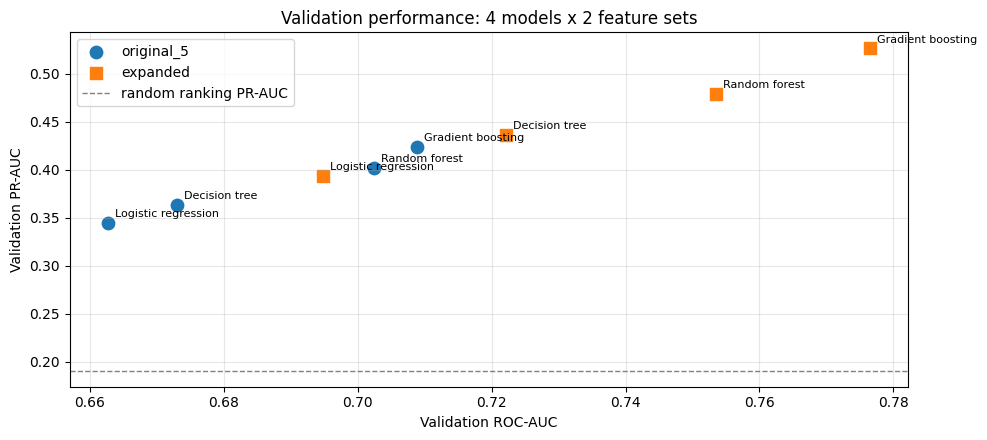

In [7]:
validation_results = pd.concat([results_original, results_expanded], ignore_index=True)
validation_results.to_csv(pf.MODELS / "validation_results.csv", index=False)

pivot = validation_results.pivot(index="Model", columns="Feature set", values=["PR-AUC", "ROC-AUC", "Lift@10%"])
display(pivot)

best = validation_results.sort_values("PR-AUC", ascending=False).iloc[0]
FINAL_SET, FINAL_MODEL = best["Feature set"], best["Model"]
final = (models_original if FINAL_SET == "original_5" else models_expanded)[FINAL_MODEL]
print(f"Selected: {FINAL_MODEL} with the {FINAL_SET} feature set "
      f"(validation PR-AUC {best['PR-AUC']:.4f}, ROC-AUC {best['ROC-AUC']:.4f})")

fig, ax = plt.subplots(figsize=(10, 4.5))
for fs, marker in [("original_5", "o"), ("expanded", "s")]:
    sub = validation_results[validation_results["Feature set"] == fs]
    ax.scatter(sub["ROC-AUC"], sub["PR-AUC"], marker=marker, s=80, label=fs)
    for _, r in sub.iterrows():
        ax.annotate(r["Model"], (r["ROC-AUC"], r["PR-AUC"]), xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.axhline(y_val.mean(), color="gray", ls="--", lw=1, label="random ranking PR-AUC")
ax.set_xlabel("Validation ROC-AUC"); ax.set_ylabel("Validation PR-AUC"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Validation performance: 4 models x 2 feature sets")
plt.tight_layout(); plt.show()

# Free the models that were not selected.
del models_original, models_expanded

## 6.7 Calibrate the selected model

Class weighting improves ranking but inflates predicted probabilities. To report a **likelihood of failure** that can be read at face value, the selected model is frozen and its scores are mapped to probabilities with isotonic regression fitted on the validation set. Isotonic calibration is a step function, so bids with different raw scores can end up with the same probability. These ties blur the ranking slightly, so **ranking metrics (ROC-AUC, PR-AUC and the review-queue metrics) are computed on the raw scores**. The calibrated probabilities are used where a probability is needed: the Brier score, the reliability chart and the probability cutoff in §6.8.1.

Mean predicted probability on test: uncalibrated 0.420 | calibrated 0.190 | observed failure rate 0.192
Brier score on test: uncalibrated 0.1818 | calibrated 0.1246
Distinct scores on test: raw 82,894 | calibrated 185 (ranking metrics below use the raw scores)


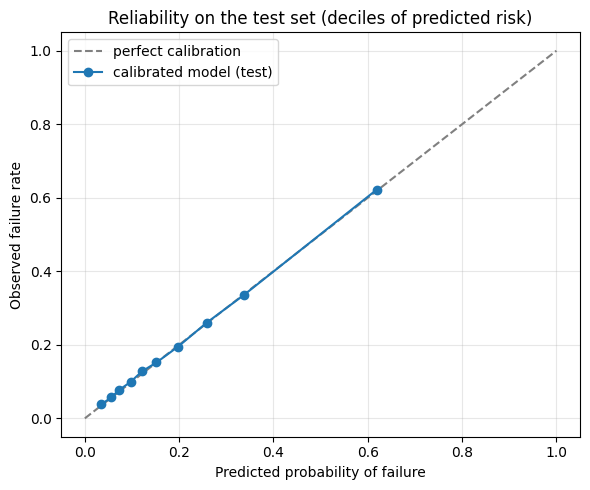

In [8]:
numeric, categorical = pf.FEATURE_SETS[FINAL_SET]
X_val = pf.model_frame(val, numeric, categorical)
X_test = pf.model_frame(test, numeric, categorical)

calibrated = CalibratedClassifierCV(FrozenEstimator(final), method="isotonic").fit(X_val, y_val)
raw_test = final.predict_proba(X_test)[:, 1]
prob_test = calibrated.predict_proba(X_test)[:, 1]

print(f"Mean predicted probability on test: uncalibrated {raw_test.mean():.3f} | calibrated {prob_test.mean():.3f} | observed failure rate {y_test.mean():.3f}")
print(f"Brier score on test: uncalibrated {brier_score_loss(y_test, raw_test):.4f} | calibrated {brier_score_loss(y_test, prob_test):.4f}")
print(f"Distinct scores on test: raw {len(np.unique(raw_test)):,} | calibrated {len(np.unique(prob_test)):,} "
      "(ranking metrics below use the raw scores)")

frac_pos, mean_pred = calibration_curve(y_test, prob_test, n_bins=10, strategy="quantile")
plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
plt.plot(mean_pred, frac_pos, "o-", label="calibrated model (test)")
plt.xlabel("Predicted probability of failure"); plt.ylabel("Observed failure rate")
plt.title("Reliability on the test set (deciles of predicted risk)"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6.8 Test-set evaluation of the final model

This is the only use of the test set. Ranking metrics use the raw scores of the selected model (§6.7).

,Model,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%,Brier (calibrated)
0,Gradient boosting (expanded),86985,0.1918,0.7724,0.5221,0.6108,0.3184,3.1843,0.1246


,Review share,Notices reviewed,Precision@k,Recall@k,Lift@k
0,top 5%,4349,0.7593,0.1979,3.9580
1,top 10%,8698,0.6108,0.3184,3.1843
2,top 20%,17397,0.4689,0.4889,2.4443
3,top 30%,26096,0.3974,0.6215,2.0718
4,top 50%,43492,0.3064,0.7986,1.5973


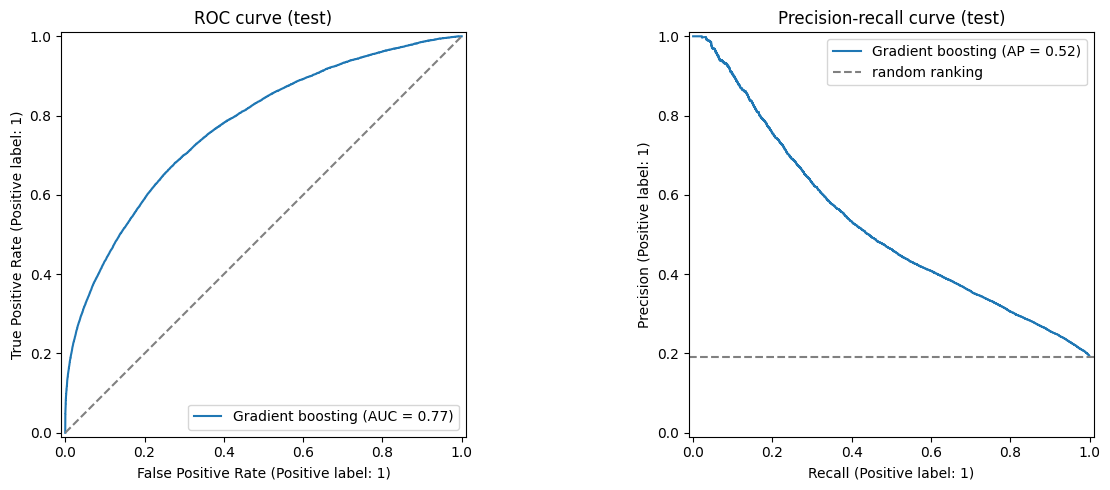

Reviewing the top 10% of test notices by predicted risk (8,698 notices) finds 61.1% failures among them, vs 19.2% at random (3.18x lift), and captures 31.8% of all failed bids in the test set.


In [9]:
test_summary = pd.DataFrame([{"Model": f"{FINAL_MODEL} ({FINAL_SET})", **pf.summary_metrics(y_test, raw_test),
                              "Brier (calibrated)": brier_score_loss(y_test, prob_test)}])
display(test_summary)

queue = pf.queue_metrics(y_test, raw_test)
display(queue)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_test, raw_test, ax=axes[0], name=FINAL_MODEL)
axes[0].plot([0, 1], [0, 1], "--", color="gray")
PrecisionRecallDisplay.from_predictions(y_test, raw_test, ax=axes[1], name=FINAL_MODEL)
axes[1].axhline(y_test.mean(), ls="--", color="gray", label="random ranking")
axes[1].legend()
axes[0].set_title("ROC curve (test)"); axes[1].set_title("Precision-recall curve (test)")
plt.tight_layout(); plt.show()

k = queue.set_index("Review share").loc["top 10%"]
print(f"Reviewing the top 10% of test notices by predicted risk ({int(k['Notices reviewed']):,} notices) finds "
      f"{k['Precision@k'] * 100:.1f}% failures among them, vs {y_test.mean() * 100:.1f}% at random "
      f"({k['Lift@k']:.2f}x lift), and captures {k['Recall@k'] * 100:.1f}% of all failed bids in the test set.")

### 6.8.1 Confusion matrices at two cutoffs

The model outputs a probability, so a confusion matrix needs a cutoff that turns it into a yes/no flag. Two are shown:

- **Top 10% of notices by predicted risk.** This matches the review-queue use: staff review a fixed share of notices. It is the same cutoff as Precision@10% and Recall@10% above, ranked by the raw score.
- **Calibrated probability ≥ 0.5.** The conventional classifier view: flag a notice when failure is judged more likely than not.

Each cell shows the count and its share of the actual class. The shading follows that share, so the diagonal reads as recall for failures (bottom right) and specificity for awards (top left). The table also gives accuracy, F1, balanced accuracy and MCC. Accuracy alone is misleading here: flagging nothing would score 80%.

,Cutoff,Flagged,TP,FP,FN,TN,Accuracy,Precision,Recall,Specificity,F1,Balanced accuracy,MCC
0,Top 10% of notices by predicted risk,8698,5313,3385,11373,66914,0.8303,0.6108,0.3184,0.9518,0.4186,0.6351,0.3547
1,Calibrated probability ≥ 0.5,5024,3674,1350,13012,68949,0.8349,0.7313,0.2202,0.9808,0.3385,0.6005,0.3392


,Predicted Awarded,Predicted Failed or Cancelled
Top 10% of notices by predicted risk,,
Actual Awarded,66914,3385
Actual Failed or Cancelled,11373,5313


,Predicted Awarded,Predicted Failed or Cancelled
Calibrated probability ≥ 0.5,,
Actual Awarded,68949,1350
Actual Failed or Cancelled,13012,3674


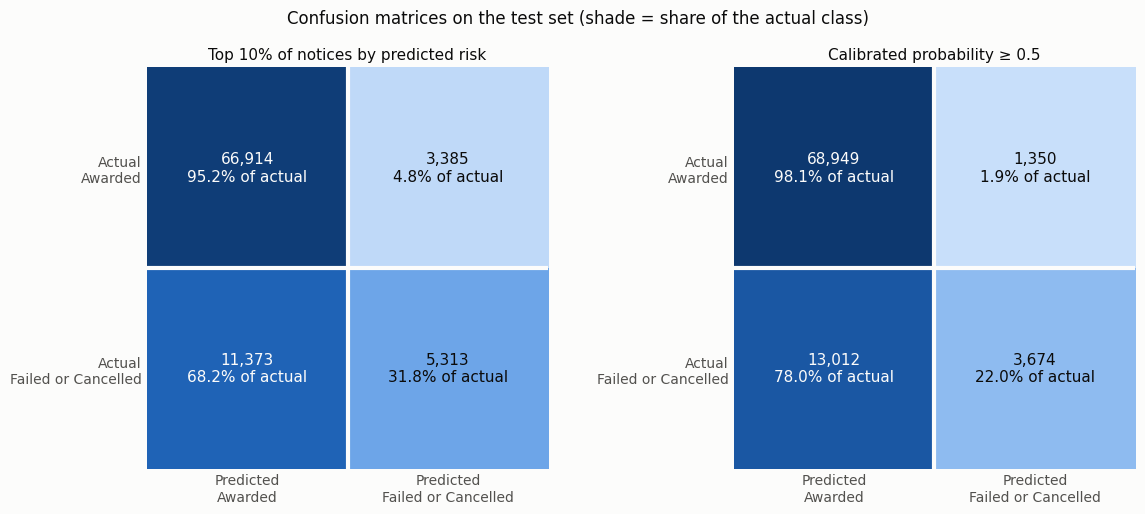

In [10]:
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score, matthews_corrcoef

k10 = int(round(len(raw_test) * 0.10))
flag_top10 = np.zeros(len(raw_test), dtype=int)
flag_top10[np.argsort(-raw_test, kind="stable")[:k10]] = 1  # same ranking rule as pf.queue_metrics
cutoffs = {"Top 10% of notices by predicted risk": flag_top10,
           "Calibrated probability ≥ 0.5": (prob_test >= 0.5).astype(int)}
labels = ["Awarded", "Failed or Cancelled"]

rows, matrices = [], {}
for name, pred in cutoffs.items():
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    matrices[name] = cm
    tn, fp, fn, tp = cm.ravel()
    rows.append({"Cutoff": name, "Flagged": int(pred.sum()), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                 "Accuracy": (tp + tn) / cm.sum(), "Precision": tp / (tp + fp), "Recall": tp / (tp + fn),
                 "Specificity": tn / (tn + fp), "F1": f1_score(y_test, pred),
                 "Balanced accuracy": balanced_accuracy_score(y_test, pred), "MCC": matthews_corrcoef(y_test, pred)})
cm_summary = pd.DataFrame(rows)
display(cm_summary)
for name, cm in matrices.items():
    display(pd.DataFrame(cm, index=[f"Actual {l}" for l in labels], columns=[f"Predicted {l}" for l in labels])
            .rename_axis(name))

# Single-hue sequential scale (light = low share, dark = high share); ink switches to light text on dark cells.
seq_blue = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])
SURFACE, INK, INK_2 = "#fcfcfb", "#0b0b0b", "#52514e"
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), facecolor=SURFACE)
for ax, (name, cm) in zip(axes, matrices.items()):
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap=seq_blue, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n{share[i, j]:.1%} of actual", ha="center", va="center", fontsize=11,
                    color=SURFACE if share[i, j] >= 0.5 else INK)
    ax.axhline(0.5, color=SURFACE, lw=3); ax.axvline(0.5, color=SURFACE, lw=3)  # gap between cells
    ax.set_xticks([0, 1], [f"Predicted\n{l}" for l in labels])
    ax.set_yticks([0, 1], [f"Actual\n{l}" for l in labels])
    ax.tick_params(length=0, colors=INK_2)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(name, fontsize=11, color=INK)
fig.suptitle("Confusion matrices on the test set (shade = share of the actual class)", color=INK)
plt.tight_layout(); plt.show()

**Reading the matrices.** Both cutoffs rarely flag an awarded notice (specificity 95% and 98%), so a flag is usually worth a look: 61% of top-10% flags and 73% of flags at 0.5 are real failures, against 19% at random. The cost is recall: at these cutoffs most failures (68% and 78%) are not flagged, because many failed or cancelled notices look like ordinary ones at publication. The top-10% cutoff catches more failures (5,313 vs 3,674) for more false alarms (3,385 vs 1,350), and has the higher F1 (0.42 vs 0.34) and MCC (0.35 vs 0.34). Accuracy is about 83% at both cutoffs, barely above the 81% of flagging nothing, which is why the ranking metrics above are the main evaluation. A team that can review more notices should use a larger share: at 30%, the queue catches 62% of failures (§6.8).

## 6.9 Test performance by source system and by year

The test set is random, so it mixes years and systems. Splitting the results shows whether performance holds across the merged sources. PhilGEPS 2.0 bids have a much higher failure rate than 1.5 bids. Because of this, the PR-AUC of the two systems is not directly comparable; compare each system's PR-AUC with its own failure rate, i.e. its lift.

In [11]:
test_scored = test.assign(score=raw_test)
def by_group(col):
    rows = []
    for g, sub in test_scored.groupby(col, observed=True):
        if sub.Target_Failed.nunique() == 2 and len(sub) >= 200:
            rows.append({col: g, **pf.summary_metrics(sub.Target_Failed, sub.score)})
    return pd.DataFrame(rows)

display(by_group("Source System"))
display(by_group("published_year"))

,Source System,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,1.5,85713,0.1890,0.7708,0.5157,0.5992,0.3170,3.1703
1,2.0,1272,0.3813,0.7709,0.6996,0.8425,0.2206,2.2097


,published_year,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,2023,29736,0.1896,0.7631,0.4994,0.5868,0.3096,3.0952
1,2024,33282,0.1801,0.7802,0.5119,0.5820,0.3232,3.2323
2,2025,13030,0.1850,0.7891,0.5608,0.6539,0.3535,3.5353
3,2026,10937,0.2419,0.7551,0.5619,0.6865,0.2838,2.8375


## 6.10 Sensitivity: counting only failed biddings as failures

The main target counts `Failed` and `Cancelled` bids as procurement failures. Here the selected configuration is refitted with `Target_Failed_Only`, where Failed = 1, Awarded = 0 and Cancelled bids are left out. Two questions:

1. How well can the narrower *failed bidding* outcome be predicted?
2. Does the main model, trained on Failed or Cancelled, still rank failed bids above awarded ones? This is checked on the same held-out bids.

**Split.** The sensitivity population (Awarded and Failed bids) is a subset of the main population, so every bid keeps its assignment from §6.1. The sensitivity model never trains on a bid from the main test set.

In [12]:
# Sensitivity population: Awarded and Failed bids only (Cancelled left out).
# Every one of these bids is also in the main population, so it keeps its split from §6.1.
sens = labelled[labelled["Target_Failed_Only"].notna()]
s_train, s_test = sens[sens.split == "train"], sens[sens.split == "test"]
y_s_test = s_test.Target_Failed_Only.astype(int)
print("Sensitivity split:", sens.split.value_counts().to_dict())

sens_model = make_models(numeric, categorical)[FINAL_MODEL]
sens_model.fit(pf.model_frame(s_train, numeric, categorical), s_train.Target_Failed_Only.astype(int))
X_s_test = pf.model_frame(s_test, numeric, categorical)
s_score = sens_model.predict_proba(X_s_test)[:, 1]
main_on_s = final.predict_proba(X_s_test)[:, 1]

comparison = pd.DataFrame([
    {"Trained on": "Failed or Cancelled vs Awarded (main)", "Evaluated on": "main test set (Failed or Cancelled vs Awarded)",
     **pf.summary_metrics(y_test, raw_test)},
    {"Trained on": "Failed vs Awarded", "Evaluated on": "test set without Cancelled (Failed vs Awarded)",
     **pf.summary_metrics(y_s_test, s_score)},
    {"Trained on": "Failed or Cancelled vs Awarded (main)", "Evaluated on": "test set without Cancelled (Failed vs Awarded)",
     **pf.summary_metrics(y_s_test, main_on_s)},
])
display(comparison)
print(f"Sensitivity population: {len(sens):,} bids, positive rate {sens.Target_Failed_Only.mean() * 100:.1f}%")

Sensitivity split: {'train': 371473, 'validation': 79854, 'test': 79546}


,Trained on,Evaluated on,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,Failed or Cancelled vs Awarded (main),main test set (Failed or Cancelled vs Awarded),86985,0.1918,0.7724,0.5221,0.6108,0.3184,3.1843
1,Failed vs Awarded,test set without Cancelled (Failed vs Awarded),79546,0.1162,0.8417,0.5113,0.5043,0.4339,4.3385
2,Failed or Cancelled vs Awarded (main),test set without Cancelled (Failed vs Awarded),79546,0.1162,0.8169,0.4841,0.4857,0.4179,4.1784


Sensitivity population: 530,873 bids, positive rate 11.6%


## 6.11 Sensitivity: adding the 2025 Q3–Q4 bids back

The 2025 Q3–Q4 bids were left out because their outcomes are incomplete (notebook 01, §5.3). Here they are added back, each in the set it was assigned to in §6.1, and the selected configuration is refitted. The comparison shows how much the exclusion changes the results on the main test set, and how either model does on the 2025 Q3–Q4 test bids themselves.

In [13]:
excluded = all_labelled[~all_labelled["in_model_scope"]]
wide_train = pd.concat([train, excluded[excluded.split == "train"]], ignore_index=True)
model_q34 = make_models(numeric, categorical)[FINAL_MODEL]
model_q34.fit(pf.model_frame(wide_train, numeric, categorical), wide_train.Target_Failed.astype(int))

q34_test = excluded[excluded.split == "test"]
X_q34 = pf.model_frame(q34_test, numeric, categorical)
q34_comparison = pd.DataFrame([
    {"Training data": "Main (2025 Q3–Q4 excluded)", "Evaluated on": "main test set", **pf.summary_metrics(y_test, raw_test)},
    {"Training data": "Including 2025 Q3–Q4", "Evaluated on": "main test set",
     **pf.summary_metrics(y_test, model_q34.predict_proba(X_test)[:, 1])},
    {"Training data": "Main (2025 Q3–Q4 excluded)", "Evaluated on": "2025 Q3–Q4 test bids",
     **pf.summary_metrics(q34_test.Target_Failed, final.predict_proba(X_q34)[:, 1])},
    {"Training data": "Including 2025 Q3–Q4", "Evaluated on": "2025 Q3–Q4 test bids",
     **pf.summary_metrics(q34_test.Target_Failed, model_q34.predict_proba(X_q34)[:, 1])},
])
display(q34_comparison)
print(f"2025 Q3–Q4 labelled bids: {len(excluded):,}; failure rate {excluded.Target_Failed.mean() * 100:.1f}% "
      f"(cancelled {(excluded.status == 'Cancelled').mean() * 100:.1f}% vs {(labelled.status == 'Cancelled').mean() * 100:.1f}% in scope)")

,Training data,Evaluated on,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,Main (2025 Q3–Q4 excluded),main test set,86985,0.1918,0.7724,0.5221,0.6108,0.3184,3.1843
1,Including 2025 Q3–Q4,main test set,86985,0.1918,0.7727,0.5229,0.6077,0.3168,3.1681
2,Main (2025 Q3–Q4 excluded),2025 Q3–Q4 test bids,5207,0.3463,0.7249,0.6140,0.7582,0.2191,2.1895
3,Including 2025 Q3–Q4,2025 Q3–Q4 test bids,5207,0.3463,0.7555,0.6484,0.8004,0.2313,2.3115


2025 Q3–Q4 labelled bids: 35,178; failure rate 34.6% (cancelled 21.4% vs 8.5% in scope)


## 6.12 Save the final model

The fitted pipeline, the calibrated model and the configuration are saved under `data/processed/models/`, which Git ignores, for use in notebook 03.

In [14]:
joblib.dump(final, pf.MODELS / "final_pipeline.joblib", compress=3)
joblib.dump(calibrated, pf.MODELS / "final_calibrated.joblib", compress=3)
config = {"feature_set": FINAL_SET, "model": FINAL_MODEL,
          "numeric": numeric, "categorical": categorical, "excluded_quarters": pf.INCOMPLETE_QUARTERS,
          "validation_pr_auc": float(best["PR-AUC"]),
          "test": {k: float(v) for k, v in pf.summary_metrics(y_test, raw_test).items()},
          "test_brier_calibrated": float(brier_score_loss(y_test, prob_test))}
(pf.MODELS / "final_config.json").write_text(json.dumps(config, indent=2))
queue.to_csv(pf.MODELS / "test_queue_metrics.csv", index=False)
comparison.to_csv(pf.MODELS / "sensitivity_failed_only.csv", index=False)
q34_comparison.to_csv(pf.MODELS / "sensitivity_2025q3q4.csv", index=False)
print(json.dumps(config, indent=2))

{
  "feature_set": "expanded",
  "model": "Gradient boosting",
  "numeric": [
    "log_approved_budget",
    "bidding_window_days",
    "log_n_line_items",
    "log_contract_duration_days",
    "multi_funding_source",
    "n_prior_attempts"
  ],
  "categorical": [
    "Funding Source",
    "Business Category",
    "Region",
    "published_month",
    "Classification",
    "PE Organization Type (Grouped)",
    "Government Branch",
    "Funding Instrument",
    "Trade Agreement",
    "Lot Type",
    "published_dayofweek",
    "Source System",
    "previous_attempt"
  ],
  "excluded_quarters": [
    "2025Q3",
    "2025Q4"
  ],
  "validation_pr_auc": 0.5266339500670224,
  "test": {
    "n": 86985.0,
    "failure rate": 0.1918261769270564,
    "ROC-AUC": 0.7724422928055783,
    "PR-AUC": 0.5221361209914487,
    "Precision@10%": 0.6108300758795125,
    "Recall@10%": 0.3184106436533621,
    "Lift@10%": 3.1842894732338127
  },
  "test_brier_calibrated": 0.12461265297044577
}
